# 01. Load and audit the data

Owner: Jalil-g. Issue #1.

## Goal

Check the five competition files and find duplicate groups before splitting. Save safe evidence; keep passages private.

## Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from itertools import combinations
import hashlib, importlib.metadata, json, math, platform, re, shutil, subprocess, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from dotenv import load_dotenv

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SEED = 42
CONFIG = {"seed": SEED, "normalization": "NFKC, casefold, Unicode word tokens",
          "shingle_words": 5, "jaccard_numerator": 85, "jaccard_denominator": 100,
          "candidate_search": "global lexical prefix, integer length filter, exact intersection"}
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace notebooks/01_data_setup.ipynb"
START = time.perf_counter()
UTC = datetime.now(timezone.utc).isoformat()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
PRIVATE = ROOT / "artifacts" / "01_data_setup" / RUN_ID
PRIVATE.mkdir(parents=True, exist_ok=False)
RESULTS = ROOT / "results" / "01_data_setup"
RESULTS.mkdir(parents=True, exist_ok=True)
REVISION = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip()
SOURCE_HASH = hashlib.sha256("\n".join(c["source"] if isinstance(c["source"], str) else "".join(c["source"]) for c in json.loads((ROOT / "notebooks/01_data_setup.ipynb").read_text())["cells"]).encode()).hexdigest()
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def canonical_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()
def write_new(path, value):
    with Path(path).open("x") as handle:
        json.dump(value, handle, indent=2, sort_keys=True, allow_nan=False)
        handle.write("\n")
versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "kagglehub", "python-dotenv", "nbconvert", "ipykernel"]}
versions["python"] = platform.python_version()
base_record = {"run_id": RUN_ID, "utc": UTC, "git_sha": REVISION, "notebook_source_sha256": SOURCE_HASH,
               "command": COMMAND, "versions": versions, "lock_sha256": digest(ROOT / "uv.lock"),
               "seed": SEED, "config": CONFIG, "config_sha256": canonical_hash(CONFIG),
               "split_sha256": None, "fit_rows": 0, "eval_rows": 0, "metrics": {"validation_auroc": None}}
def preserve_failure(exc):
    # Tracebacks can contain passages. Keep them local; publish only the exception type.
    write_new(RESULTS / f"{RUN_ID}-failed.json", dict(base_record, status="failed",
              error_type=type(exc).__name__, runtime_seconds=time.perf_counter() - START))

/Users/jaliljabbarli/Cornell/Cornell-Text-Authorship/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Checks

Read IDs as strings. Check the starter by ID, text, and label. A changed byte hash stops the run before any saved input is replaced.

In [2]:
SCHEMAS = {
    "train.csv": (["id", "text", "label"], 10000),
    "unlabeled.csv": (["id", "text"], 3000),
    "test.csv": (["id", "text"], 3000),
    "train_starter_2000.csv": (["id", "text", "label"], 2000),
    "sample_submission.csv": (["id", "label"], 3000),
}
def validate_frames(frames):
    for name, (columns, count) in SCHEMAS.items():
        frame = frames[name]
        assert list(frame.columns) == columns, f"Schema mismatch: {name}"
        assert len(frame) == count, f"Row count mismatch: {name}"
        assert frame.id.notna().all() and frame.id.is_unique, f"Bad IDs: {name}"
        assert frame.id.map(lambda x: isinstance(x, str) and bool(x.strip())).all(), f"Empty ID: {name}"
        if "text" in columns:
            assert frame.text.notna().all() and frame.text.str.strip().ne("").all(), f"Empty text: {name}"
        if name in ("train.csv", "train_starter_2000.csv"):
            assert frame.label.notna().all() and frame.label.isin([0, 1]).all(), f"Bad labels: {name}"
    train = frames["train.csv"].set_index("id")
    starter = frames["train_starter_2000.csv"].set_index("id")
    assert train.label.value_counts().to_dict() == {0: 5000, 1: 5000}, "Class balance mismatch"
    assert starter.index.isin(train.index).all(), "Starter has extra IDs"
    assert starter.equals(train.loc[starter.index]), "Starter differs from training rows"
    assert set(frames["sample_submission.csv"].id) == set(frames["test.csv"].id), "Sample IDs mismatch"

def load_data():
    load_dotenv(ROOT / ".env", override=False)
    cache = Path(kagglehub.competition_download("cornell-tech-cs-5785-combined-2026-ai-vs-human-text"))
    hashes = {name: digest(cache / name) for name in SCHEMAS}
    manifest_path = ROOT / "configs" / "data_manifest.json"
    if manifest_path.exists():
        assert json.loads(manifest_path.read_text())["sha256"] == hashes, "Downloaded data changed"
    raw = ROOT / "data" / "raw"
    raw.mkdir(parents=True, exist_ok=True)
    for name in SCHEMAS:
        target = raw / name
        if target.exists():
            assert digest(target) == hashes[name], "Local raw data changed"
    frames = {name: pd.read_csv(cache / name, dtype={"id": "string"}) for name in SCHEMAS}
    validate_frames(frames)
    for name in SCHEMAS:
        if not (raw / name).exists():
            shutil.copyfile(cache / name, raw / name)
        assert digest(raw / name) == hashes[name]
    manifest = {"sha256": hashes, "download_checked_utc": datetime.now(timezone.utc).isoformat(),
                "competition": "cornell-tech-cs-5785-combined-2026-ai-vs-human-text"}
    manifest_path.parent.mkdir(exist_ok=True)
    if not manifest_path.exists():
        write_new(manifest_path, manifest)
    return frames, hashes, manifest_path

## Method

Normalize audit copies only. Use sets of five-word shingles. For fewer than five words, use the whole token tuple.

For set size n, index the first n - ceil(.85n) + 1 shingles in one global lexical order. Any pair with Jaccard at least .85 must share a prefix token: otherwise the earlier first shared token leaves fewer than ceil(.85n) possible shared tokens in one set. Check candidate lengths, then verify the exact intersection with integer arithmetic. No approximate search.

Union exact-text and near-duplicate edges across train, unlabeled, and test. Starter copies are excluded. Save row membership only under ignored artifacts.

In [3]:
def shingles(text):
    words = re.findall(r"\w+", unicodedata.normalize("NFKC", text).casefold())
    if len(words) < 5:
        return {tuple(words)}
    return {tuple(words[i:i + 5]) for i in range(len(words) - 4)}

def near_pairs(sets):
    postings = defaultdict(list)
    pairs = []
    candidates_checked = 0
    for i, current in enumerate(sets):
        size = len(current)
        prefix = sorted(current)[:size - (85 * size + 99) // 100 + 1]
        candidates = set()
        for token in prefix:
            for j in postings[token]:
                other_size = len(sets[j])
                if 100 * min(size, other_size) >= 85 * max(size, other_size):
                    candidates.add(j)
        for j in sorted(candidates):
            candidates_checked += 1
            intersection = len(current & sets[j])
            union = size + len(sets[j]) - intersection
            if 100 * intersection >= 85 * union:
                pairs.append((j, i))
        for token in prefix:
            postings[token].append(i)
    return pairs, candidates_checked

# Compare the lossless filter with brute force, including the .85 boundary.
rng = np.random.default_rng(SEED)
fixtures = [set(rng.choice(30, size=int(rng.integers(1, 25)), replace=False)) for _ in range(100)]
fixtures += [set(range(20)), set(range(17)), set(range(16)), {100}, {100}]
expected = {(j, i) for i in range(len(fixtures)) for j in range(i)
            if 100 * len(fixtures[j] & fixtures[i]) >= 85 * len(fixtures[j] | fixtures[i])}
assert set(near_pairs(fixtures)[0]) == expected
assert shingles("Ａ BC") == shingles("a bc")
assert shingles("!!!") == {()}

def audit(frames):
    rows = pd.concat([frames[name].assign(file=name) for name in
                      ["train.csv", "unlabeled.csv", "test.csv"]], ignore_index=True)
    sets = [shingles(text) for text in rows.text]
    near, candidate_count = near_pairs(sets)
    exact_groups = defaultdict(list)
    for i, text in enumerate(rows.text):
        exact_groups[text].append(i)
    exact = [pair for indices in exact_groups.values() for pair in combinations(indices, 2)]
    parent = list(range(len(rows)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for a, b in exact + near:
        parent[find(b)] = find(a)
    groups = defaultdict(list)
    for i in range(len(rows)):
        groups[find(i)].append(i)
    components = [[{"file": str(rows.iloc[i].file), "id": str(rows.iloc[i].id)} for i in indices]
                  for indices in groups.values() if len(indices) > 1]
    summary = []
    for name, frame in frames.items():
        entry = {"file": name, "rows": len(frame)}
        if "text" in frame:
            lengths = frame.text.str.split().str.len()
            entry.update({"words_min": int(lengths.min()), "words_median": float(lengths.median()),
                          "words_mean": float(lengths.mean()), "words_max": int(lengths.max()),
                          "characters_mean": float(frame.text.str.len().mean())})
        if name in ("train.csv", "train_starter_2000.csv"):
            entry["class_counts"] = {str(k): int(v) for k, v in frame.label.value_counts().items()}
        summary.append(entry)
    def pair_counts(pairs):
        return dict(Counter(" / ".join(sorted([str(rows.iloc[a].file), str(rows.iloc[b].file)])) for a, b in pairs))
    conflicts = sum(len(set(rows.iloc[indices].loc[lambda x: x.file == "train.csv", "label"].dropna())) > 1
                    for indices in groups.values() if len(indices) > 1)
    return {"files": summary, "exact_pair_counts": pair_counts(exact), "near_pair_counts": pair_counts(near),
            "candidate_pairs_checked": candidate_count, "duplicate_components": len(components),
            "duplicate_rows": sum(map(len, components)), "conflicting_training_label_components": conflicts}, components

## Run

In [4]:
try:
    frames, data_hashes, manifest_path = load_data()
    base_record["data_sha256"] = data_hashes
    audit_start = time.perf_counter()
    summary, components = audit(frames)
    audit_seconds = time.perf_counter() - audit_start
    components_path = PRIVATE / "duplicate_components.json"
    write_new(components_path, {"data_sha256": data_hashes, "config": CONFIG, "components": components})
except Exception as exc:
    preserve_failure(exc)
    raise RuntimeError("Audit failed. See saved failure status; inspect private inputs locally.") from None

## Results

Lengths use whitespace-separated words. Duplicate counts include pairs within each file and across files.

,file,rows,words_min,words_median,words_mean,words_max,characters_mean,class_counts
0,train.csv,10000,75.0,206.0,208.708700,350.0,1260.909000,"{'0': 5000, '1': 5000}"
1,unlabeled.csv,3000,75.0,206.5,210.251333,350.0,1268.075000,NaN
2,test.csv,3000,75.0,213.0,216.972333,350.0,1274.930333,NaN
3,train_starter_2000.csv,2000,76.0,207.0,209.857500,349.0,1269.289000,"{'0': 1000, '1': 1000}"
4,sample_submission.csv,3000,NaN,NaN,NaN,NaN,NaN,NaN


{
  "exact_pair_counts": {},
  "near_pair_counts": {},
  "candidate_pairs_checked": 108271,
  "duplicate_components": 0,
  "duplicate_rows": 0,
  "conflicting_training_label_components": 0
}
Audit runtime: 2.623 seconds


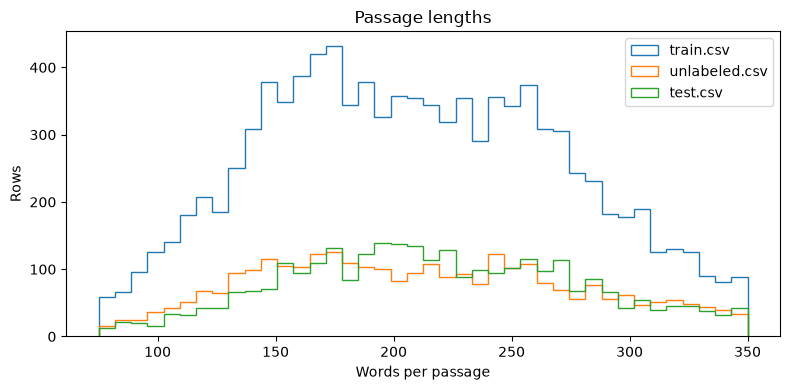

In [5]:
display(pd.DataFrame(summary["files"]))
print(json.dumps({k: v for k, v in summary.items() if k != "files"}, indent=2))
print(f"Audit runtime: {audit_seconds:.3f} seconds")
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["train.csv", "unlabeled.csv", "test.csv"]:
    ax.hist(frames[name].text.str.split().str.len(), bins=40, histtype="step", label=name)
ax.set(xlabel="Words per passage", ylabel="Rows", title="Passage lengths")
ax.legend()
fig.tight_layout()
plot_path = RESULTS / f"{RUN_ID}-lengths.png"
fig.savefig(plot_path, dpi=140)
plt.show()

## Takeaway

- Checked schemas, labels, starter membership, and sample IDs.
- Duplicate counts above are measured. No model score exists at this stage.
- Next: freeze the split in #2 using these data hashes and duplicate groups.

## Save

Keep the raw files and component membership local. Commit the input manifest, aggregate audit, and length plot. Each run gets a new record.

In [6]:
record = dict(base_record, status="completed", audit=summary, audit_sha256=canonical_hash(summary),
              data_manifest_sha256=digest(manifest_path), audit_seconds=audit_seconds,
              runtime_seconds=time.perf_counter() - START,
              artifacts={str(components_path.relative_to(ROOT)): digest(components_path),
                         str(plot_path.relative_to(ROOT)): digest(plot_path)})
write_new(RESULTS / f"{RUN_ID}.json", record)
print("Saved aggregate audit. Private component membership stays under artifacts/.")

Saved aggregate audit. Private component membership stays under artifacts/.
